# Discriminability gradients → `gradients.pdf`

How the result of `../figure_3/efficient_coding_schematic/` extends from one stimulus to all of them.

The schematic compares two directions at one stimulus (A, antipodal north/south): rotating the
pair, $(1, 1)$, and changing its separation, $(1, -1)$. Here every point of the
$(\theta_0, \theta_1)$ plane gets one segment per population. The segment's **angle** is the
direction in which that population discriminates a small change of stimulus **best**, and its
**length** is proportional to how well (d′ per radian along it).

Both come from a 2 × 2 matrix $J(s)$ per stimulus, with $u^\top J u$ the squared d′ of a small
displacement along $u$: the direction is $J$'s top eigenvector and the length the square root of
its top eigenvalue. $J$ is **linear Fisher information from kernel-smoothed means** of recorded
trials:

* **Smoothing.** A neuron's mean rate at a stimulus is a weighted average over *all* its 2-object
  trials, each weighted by $\exp(-d^2 / 2\sigma^2)$ with $d^2 = \Delta\theta_0^2 + \Delta\theta_1^2$
  under the closer object pairing (`KERNEL_SIGMA_DEG`).
* **Fisher.** At each plotted stimulus $s$ and along each of `N_DIRECTIONS` directions $u$, the
  bias-corrected $d'^2$ between $s \pm (\text{LF\_STEP\_DEG}/2)\,u$ — $(\Delta\mu)^2/\sigma^2 - \sum_t c_t^2$,
  the correction accounting for trials shared by the two overlapping kernels — summed over units
  and divided by $\text{LF\_STEP\_DEG}^2$. That is $u^\top J u$ in finite-difference form; fitting
  $a + b\cos2\varphi + c\sin2\varphi$ over the directions gives $J$. No Poisson model, no
  classifier, and every unit enters every point.

The direction is an axis, so the segments have no heads. Lengths share one scale across both
populations, so blue and orange can be compared directly — but only relative to each other. See
[`gradients_lib.py`](gradients_lib.py) for what is and is not controlled.

On this plot a rotation of the pair runs along the diagonal $(1, 1)$ and a change of
separation along the anti-diagonal $(1, -1)$. The empty band around $\theta_0 = \theta_1$ (and its
wrapped corners) is where no stimulus was ever shown: the two objects were never closer than
~80°.

In [1]:
import sys
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt

# The repository root (where paths.py lives), found from this notebook's folder.
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'paths.py').exists())
sys.path.insert(0, str(_root))
import paths
sys.path.insert(0, str(paths.FIGURES / 'supp_figure_3'))
import common
import gradients_lib as gl

common.set_style()

# ── CONFIG ───────────────────────────────────────────────────────────────────
# The populations: every neuron is assigned to whichever model (retinotopic or relational) fits
# it better, and each population is then the top K of its neurons by fit strength, ranked over
# both animals together (mostly Monkey P, whose fits run stronger).
SUBJECTS = ('Perle', 'Elgar')
K = 20                   # neurons in EACH population
MIN_SEP_DEG = 83.0       # grid points with the objects closer than this are left empty

# ── The measure: linear Fisher information from kernel-weighted means ───────
KERNEL_SIGMA_DEG = 20.0  # Gaussian kernel width on the (theta_0, theta_1) distance
LF_STEP_DEG = 25.0       # distance between the two stimuli compared
N_DIRECTIONS = 6         # directions through each point, evenly over [0°, 180°); at least 3
N_GRID = 12              # the (theta_0, theta_1) grid: N_GRID bins per angle (12 -> 30° cells)

# ── Figure ───────────────────────────────────────────────────────────────────
STEP = 1                 # a segment at every STEP-th grid point (1 = every one of the 12 x 12)
FIGSIZE = (3.4, 3.6)
LINE_WIDTH = 1.6
LINE_ALPHA = 0.9
COLORS = {'retinotopic': 'tab:blue', 'relational': 'tab:orange'}
DRAW_ORDER = ('retinotopic', 'relational')     # the last is drawn on top
OUTPUT = 'gradients.pdf'

## 1. The populations and their discriminability fields

In [2]:
units = gl.population_units(SUBJECTS, K)
trials = gl.load_trials(units)
mask = gl.sampled_mask(N_GRID, MIN_SEP_DEG)

J, info = gl.linear_fisher_field(trials, gl.plotted_points(mask, STEP),
                                 step_deg=LF_STEP_DEG, n_directions=N_DIRECTIONS,
                                 sigma_deg=KERNEL_SIGMA_DEG)
ne = info['n_eff_min'][np.isfinite(info['n_eff_min'])]
print(f'{len(trials["relational"])} units per population; smallest '
      f'effective trial count of any unit at a point: median {np.median(ne):.1f}, '
      f'min {ne.min():.1f}')

fields = {side: gl.top_direction(j) for side, j in J.items()}
display(gl.summary(fields, mask).round(3))

  retinotopic : 20 of 497 (fit strength 0.312–0.431, median 0.345)
  relational  : 20 of 842 (fit strength 0.374–0.612, median 0.413)
20 units per population; smallest effective trial count of any unit at a point: median 31.6, min 13.4


,n_points,median_abs_cos_rotation,frac_closer_to_rotation,median_dprime_per_rad
population,,,,
retinotopic,84,0.606,0.452,4.209
relational,84,0.988,1.000,5.361


## 2. The figure

`median_abs_cos_rotation` above is $|\cos|$ between each population's best direction and the
rotation axis $(1,1)/\sqrt2$, over every sampled grid stimulus: 1 is pure rotation, 0 pure
separation change, 0.71 halfway.

saved gradients.pdf


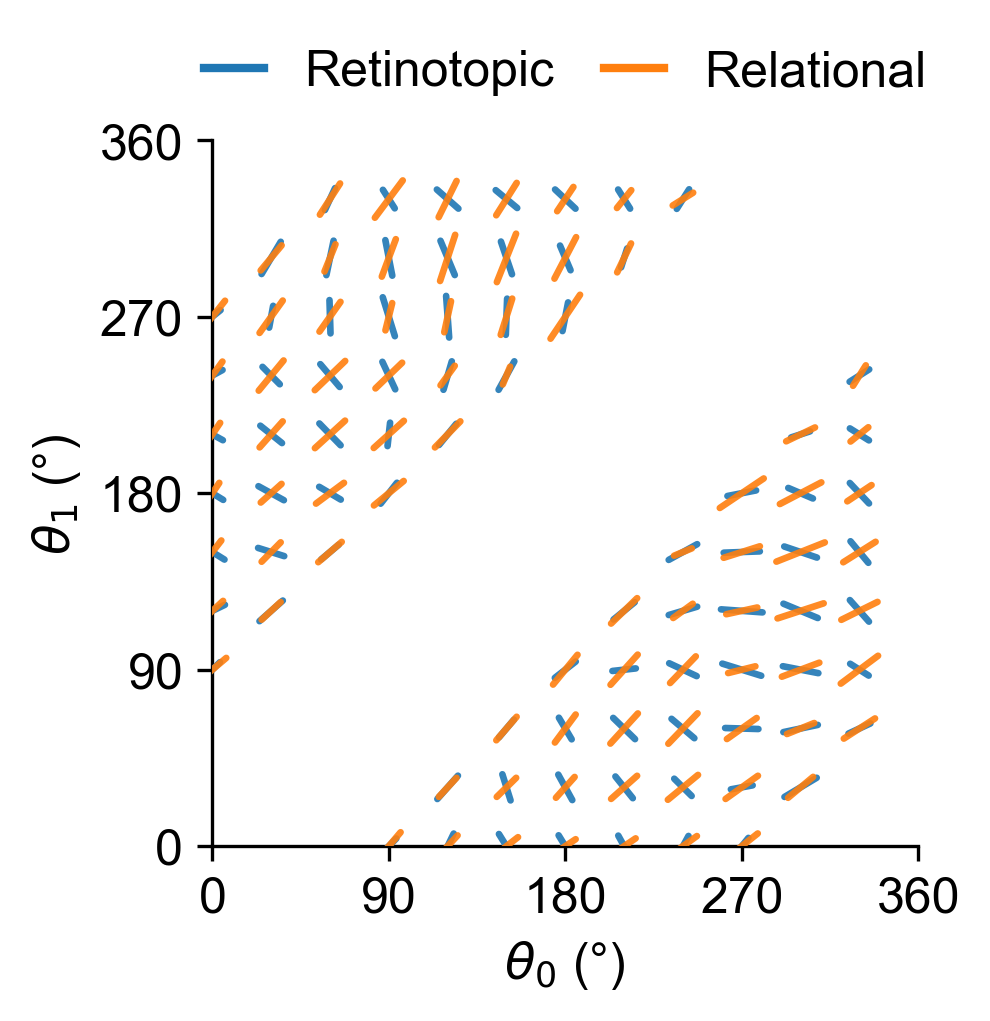

In [3]:
fig, ax = gl.plot_field(fields, mask, STEP, figsize=FIGSIZE, colors=COLORS, lw=LINE_WIDTH,
                        alpha=LINE_ALPHA, order=DRAW_ORDER)
common.save(fig, OUTPUT)
plt.show()